# Thinking Budgets From Scratch: When a Finance Data Agent Should Think Longer, Retry, or Check

**A data agent answers finance questions by writing one SQL query each. Some questions are a one-line count, and some need five business rules applied at once. This notebook turns `reasoning_effort` from `none` to `high` on 18 questions with exact answers, and reads the reasoning tokens the API bills. Then it spends the money another way: five cheap attempts, picked by a vote, by a model, or by a check that the regional split adds up to the ledger's total. Extra thinking bought almost nothing on the easy questions, paid off at its first step on the medium ones, and could not fix the rule the hard ones misread. The best setup was cheaper than thinking hard on every question: one cheap attempt, a check in code, and `high` only when the check failed.**

## The one idea

A reasoning model can spend more on one answer in two ways. It can **think longer** inside one call. On the OpenAI API that is the `reasoning_effort` setting, and the thinking is billed at the output price ([OpenAI reasoning guide](https://developers.openai.com/api/docs/guides/reasoning)). Or you can **search**: make several attempts and keep one.

Thinking needs no selector, but every question pays for it, easy or hard, and longer reasoning can even make answers worse ([Inverse Scaling in Test-Time Compute, 2025](https://arxiv.org/abs/2507.14417)). Search is only as good as whatever picks the winner. With a check that runs in code, more attempts keep finding right answers; with a majority vote or a model scorer, the gains level off ([Large Language Monkeys, 2024](https://arxiv.org/abs/2407.21787)). So build the check first, then decide what to buy.

## Overview

1. A small subscription-business warehouse with planted traps, and 18 finance questions in three tiers, each with an exact answer key
2. A one-call data agent: question in, one SQLite query out, run it, score it
3. Turn the dial: every question at `none`, `low`, `medium` and `high`, logging reasoning tokens, cost and seconds
4. Spend on search instead: five cheap attempts per question, picked by a vote, by a model, or by a check in code
5. A cascade: answer cheaply, check, and escalate to `high` only when the check fails
6. Side by side, in one table and one chart
7. What went wrong, and what the check cannot see

**Requirements:** `pip install openai matplotlib` and an `OPENAI_API_KEY`. The run makes 128 calls to `gpt-5.4-mini`. This run cost $0.52 at the list prices of 2026-10-30 and took a little over a minute, because independent calls run in parallel. Outputs saved here come from a real run. Yours will differ, and on the hard questions they can differ a lot: section 6 shows how much.

> 📖 This notebook is the hands-on side of Chapter 20, "Search and Thinking Budgets", of [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--thinking-budgets-from-scratch&click=book-nb-agents-top&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-thinking-budgets-top&retarget=0&text=book-nb-agents-top), by the author of this repository.

In [1]:
# !pip install openai matplotlib
import os, json, random, sqlite3, time, datetime as dt
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import openai
import matplotlib.pyplot as plt

MODEL = "gpt-5.4-mini"
# USD per 1M tokens, from https://developers.openai.com/api/docs/pricing on 2026-10-30. Check yours.
PRICE = {"input": 0.75, "cached_input": 0.075, "output": 4.50}
EFFORTS = ["none", "low", "medium", "high"]
client = openai.OpenAI()          # reads OPENAI_API_KEY from the environment
CALLS, T_START = [], time.time()  # every API call this notebook makes, for the bill at the end

## 1. A job with a known answer

A software company sells subscriptions. Every quarter, finance asks its data agent for a few numbers per customer segment, split by region. The agent sees six tables and a glossary of metric definitions that finance signed off on.

The generator plants the traps real warehouses have. Each one is a rule the glossary states in plain words:

- Some customers moved to another sales region in 2026. `customers.region` is the current one, and `region_history` holds the past.
- Some subscriptions were cancelled early. They stop earning after the cancel date, but their daily rate stays the same.
- Some contracts are in EUR or GBP, and the exchange-rate table has no rows for USD.
- Credit notes often land in a later quarter than their invoice, and some invoices have two.

The three tiers ask for the same shape of answer, a value per region, with more rules to apply each time:

- **easy, new subscriptions:** a count with one date filter
- **medium, net billings:** invoices minus credit notes, each converted at its own month's rate
- **hard, recognized revenue:** each contract spread per day over its term, cut at the cancel date, converted at the start month's rate, and credited to the region that signed the deal

Today is 2026-10-30, so the closed quarters are Q1 to Q3. Three quarters times two segments gives six questions per tier.

In [2]:
REGIONS = ["North America", "EMEA", "APAC", "LATAM"]
SEGMENTS = ["Enterprise", "SMB"]
QUARTERS = {"Q1": ("2026-01-01", "2026-03-31"), "Q2": ("2026-04-01", "2026-06-30"), "Q3": ("2026-07-01", "2026-09-30")}

def add_months(d, k):
    y, m = d.year + (d.month - 1 + k) // 12, (d.month - 1 + k) % 12 + 1
    return dt.date(y, m, min(d.day, 28))

def make_warehouse(seed=11, n_customers=80, n_subs=260):
    rng = random.Random(seed)
    customers, history = [], []
    for c in range(1, n_customers + 1):
        seg, first = SEGMENTS[(c // 4) % 2], REGIONS[c % 4]
        if rng.random() < 0.25:                                   # trap: the account moved to another sales region in 2026
            moved = dt.date(2026, 1, 1) + dt.timedelta(days=rng.randint(30, 300))
            then = rng.choice([r for r in REGIONS if r != first])
            history += [(c, first, "2024-01-01", (moved - dt.timedelta(days=1)).isoformat()), (c, then, moved.isoformat(), None)]
            customers.append((c, f"Customer {c:03d}", seg, then))
        else:
            history.append((c, first, "2024-01-01", None))
            customers.append((c, f"Customer {c:03d}", seg, first))
    fx = [(f"{y}-{m:02d}", cur, round(base + rng.uniform(-0.04, 0.04), 4))   # trap: no rows for USD
          for y in (2025, 2026, 2027) for m in range(1, 13) for cur, base in (("EUR", 1.08), ("GBP", 1.27))]
    subs, invoices, credits = [], [], []
    for s in range(1, n_subs + 1):
        cust = rng.choice(customers)
        start = dt.date(2025, 6, 1) + dt.timedelta(days=rng.randint(0, 560))
        term = rng.choice([3, 6, 12, 12, 24])                                  # months
        end = add_months(start, term) - dt.timedelta(days=1)
        amount = round(rng.uniform(4, 90 if cust[2] == "Enterprise" else 20) * 1000 * term / 12, 2)
        cur = rng.choices(["USD", "EUR", "GBP"], [60, 25, 15])[0]
        cancel = start + dt.timedelta(days=rng.randint(20, (end - start).days - 5)) if rng.random() < 0.12 else None
        subs.append((s, cust[0], start.isoformat(), end.isoformat(), cancel and cancel.isoformat(), amount, cur))
        n_inst = -(-term // 3)                                                 # billed every 3 months, until cancelled
        for k in range(n_inst):
            day = add_months(start, 3 * k)
            if cancel and day > cancel:
                break
            each = round(amount / n_inst, 2)
            inv_amt = each if k < n_inst - 1 else round(amount - each * (n_inst - 1), 2)
            invoices.append((len(invoices) + 1, s, day.isoformat(), inv_amt))
            for _ in range(rng.choices([0, 1, 2], [85, 11, 4])[0]):            # trap: credit notes land in later quarters, some invoices get two
                credits.append((len(credits) + 1, len(invoices), (day + dt.timedelta(days=rng.randint(5, 60))).isoformat(),
                                round(inv_amt * rng.choice([0.05, 0.1, 0.25]), 2)))
    return {"customers": customers, "region_history": history, "fx_rates": fx,
            "subscriptions": subs, "invoices": invoices, "credit_notes": credits}

SCHEMA = """CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT, segment TEXT, region TEXT);  -- segment: 'Enterprise' or 'SMB'; region: the customer's CURRENT sales region (North America, EMEA, APAC, LATAM)
CREATE TABLE region_history (customer_id INTEGER, region TEXT, valid_from TEXT, valid_to TEXT);  -- one row per period a customer spent in a region; valid_to is the last day, NULL while current
CREATE TABLE subscriptions (subscription_id INTEGER PRIMARY KEY, customer_id INTEGER, start_date TEXT, end_date TEXT, cancel_date TEXT, amount REAL, currency TEXT);  -- amount: total contract value for the whole term, in currency ('USD', 'EUR' or 'GBP'); end_date is the last day of the term; cancel_date NULL unless cancelled
CREATE TABLE invoices (invoice_id INTEGER PRIMARY KEY, subscription_id INTEGER, invoice_date TEXT, amount REAL);  -- in the subscription's currency; a subscription is billed in installments
CREATE TABLE credit_notes (credit_id INTEGER PRIMARY KEY, invoice_id INTEGER, credit_date TEXT, amount REAL);  -- partial refunds against an invoice, in the invoice's currency; amount is positive
CREATE TABLE fx_rates (month TEXT, currency TEXT, usd_rate REAL);  -- month 'YYYY-MM'; USD value = amount * usd_rate; rows for EUR and GBP only (USD needs no conversion)
-- All dates are 'YYYY-MM-DD' text."""

GLOSSARY = """METRIC DEFINITIONS (finance-approved)
- New subscriptions: the number of subscriptions whose start_date falls in the period, by the customer's current region.
- Net billings (USD): invoices dated in the period minus credit notes dated in the period (whatever period the credited invoice is from). Convert each invoice and each credit note to USD at the rate for its own month. Report by the customer's current region.
- Recognized revenue (USD): a subscription's amount is earned evenly per day, over every day from start_date through end_date inclusive. A cancelled subscription earns nothing after its cancel_date (the cancel_date itself still earns; the daily rate does not change). Revenue in a period is the daily rate times the days in the period it earned. Convert at the rate for the subscription's start month. Report it in the region the customer was in on the subscription's start_date, because revenue belongs to the region that signed the deal.
- Never round intermediate or final values."""

def read_only(action, *args):          # the agent's SQL may read, never write
    allowed = (sqlite3.SQLITE_SELECT, sqlite3.SQLITE_READ, sqlite3.SQLITE_FUNCTION, sqlite3.SQLITE_RECURSIVE)
    return sqlite3.SQLITE_OK if action in allowed else sqlite3.SQLITE_DENY

TABLES = make_warehouse()
DB = sqlite3.connect(":memory:", check_same_thread=False)
DB.executescript(SCHEMA)
for name, rows in TABLES.items():
    DB.executemany(f"INSERT INTO {name} VALUES ({','.join('?' * len(rows[0]))})", rows)
DB.set_authorizer(read_only)

subs, inv = TABLES["subscriptions"], {i[0]: i for i in TABLES["invoices"]}
quarter = lambda d: (int(d[5:7]) - 1) // 3
print({name: len(rows) for name, rows in TABLES.items()})
print(f"traps: {len(TABLES['region_history']) - len(TABLES['customers'])} customers changed region in 2026, "
      f"{sum(s[4] is not None for s in subs)} subscriptions cancelled early, {sum(s[6] != 'USD' for s in subs)} billed in EUR or GBP,\n"
      f"       {sum(quarter(c[2]) != quarter(inv[c[1]][2]) or c[2][:4] != inv[c[1]][2][:4] for c in TABLES['credit_notes'])} credit notes dated in a later quarter than their invoice, "
      f"{sum(n == 2 for n in Counter(c[1] for c in TABLES['credit_notes']).values())} invoices with two credit notes")

{'customers': 80, 'region_history': 109, 'fx_rates': 72, 'subscriptions': 260, 'invoices': 925, 'credit_notes': 192}
traps: 29 customers changed region in 2026, 33 subscriptions cancelled early, 103 billed in EUR or GBP,
       68 credit notes dated in a later quarter than their invoice, 40 invoices with two credit notes


The answer key is computed in plain Python from the generated rows, never from SQL, so it cannot share a bug with the agent's queries. During development it was also checked against a hand-written query for each of the 18 questions, and they agreed. The `misread` argument is used only in section 7.

The **close report** stands in for the general ledger: finance knows each quarter's total for every metric and segment, but not the split by region. The check in section 4 uses that total. The agent never sees it.

In [3]:
def answer_key(T, misread=()):        # misread: rules to get wrong on purpose, used in section 7
    D = dt.date.fromisoformat
    cust = {c[0]: c for c in T["customers"]}
    fx = {(m, cur): r for m, cur, r in T["fx_rates"]}
    usd = lambda day, cur: (0.0 if "USD dropped" in misread else 1.0) if cur == "USD" else fx[(day[:7], cur)]
    sub = {s[0]: s for s in T["subscriptions"]}
    inv = {i[0]: i for i in T["invoices"]}
    def region_on(c, day):
        return next(r for cc, r, a, b in T["region_history"] if cc == c and a <= day and (b is None or day <= b))
    key = {}
    for q, (qa, qb) in QUARTERS.items():
        for seg in SEGMENTS:
            new, net, rev = defaultdict(float), defaultdict(float), defaultdict(float)
            for s, c, start, end, cancel, amount, cur in T["subscriptions"]:
                if cust[c][2] != seg:
                    continue
                if qa <= start <= qb:
                    new[cust[c][3]] += 1
                last = min(end, cancel) if cancel else end                       # the cancel_date still earns
                days = (D(min(last, qb)) - D(max(start, qa))).days + 1
                if days > 0:                                                     # the daily rate uses the full term
                    rate_end = last if "rate over days served" in misread else end
                    region = cust[c][3] if "current region" in misread else region_on(c, start)
                    rev[region] += amount / ((D(rate_end) - D(start)).days + 1) * days * usd(start, cur)
            for i, s, day, amount in T["invoices"]:
                c = cust[sub[s][1]]
                if c[2] == seg and qa <= day <= qb:
                    net[c[3]] += amount * usd(day, sub[s][6])
            for _, i, day, amount in T["credit_notes"]:
                s = sub[inv[i][1]]; c = cust[s[1]]
                if "credits on this quarter's invoices only" in misread and not qa <= inv[i][2] <= qb:
                    continue
                rate_day = inv[i][2] if "credit at the invoice's rate" in misread else day
                if c[2] == seg and qa <= day <= qb:
                    net[c[3]] -= amount * usd(rate_day, s[6])
            key.update({("new", q, seg): dict(new), ("net", q, seg): dict(net), ("recognized", q, seg): dict(rev)})
    return key

KEY = answer_key(TABLES)
TIERS = {"easy": ("new", "New subscriptions by region in {q} 2026, {seg} customers only."),
         "medium": ("net", "Net billings (USD) by region in {q} 2026, {seg} customers only."),
         "hard": ("recognized", "Recognized revenue (USD) by region in {q} 2026, {seg} customers only.")}
ITEMS = [{"id": f"{tier}-{q}-{seg}", "tier": tier, "question": text.format(q=q, seg=seg), "truth": KEY[(metric, q, seg)]}
         for tier, (metric, text) in TIERS.items() for q in QUARTERS for seg in SEGMENTS]

# Finance's close report has one total per metric, quarter and segment, and no regional split.
# In a real company it comes from the general ledger. Here it is the planted total.
CLOSE_REPORT = {it["id"]: sum(it["truth"].values()) for it in ITEMS}

print(f"{len(ITEMS)} questions, {len(ITEMS) // 3} per tier")
for tier in TIERS:
    it = next(i for i in ITEMS if i["tier"] == tier)
    print(f"\n[{tier}] {it['question']}\n  answer key: " + ", ".join(f"{r} {v:,.2f}" for r, v in sorted(it["truth"].items())) +
          f"\n  close report total: {CLOSE_REPORT[it['id']]:,.2f}")

18 questions, 6 per tier

[easy] New subscriptions by region in Q1 2026, Enterprise customers only.
  answer key: APAC 5.00, EMEA 4.00, LATAM 3.00, North America 7.00
  close report total: 19.00

[medium] Net billings (USD) by region in Q1 2026, Enterprise customers only.
  answer key: APAC 142,658.28, EMEA 94,452.29, LATAM 166,734.03, North America 256,919.90
  close report total: 660,764.51

[hard] Recognized revenue (USD) by region in Q1 2026, Enterprise customers only.
  answer key: APAC 175,580.35, EMEA 114,407.90, LATAM 117,490.43, North America 190,245.89
  close report total: 597,724.57


## 2. The data agent: one question, one query

The agent is one call. The system prompt holds the schema and the glossary, the user message is the question, and the reply is a JSON object holding one SQL query. The notebook runs the query on a read-only connection with a five-second limit, and grades the result twice:

- `right`: the regional split matches the answer key to within 50 cents, and counts must match exactly. Only this notebook can do this, because it needs the planted answer.
- `passes`: every row is a real region, and the split adds up to the close report's total. Production can do this, because finance has the total. This is **the check**.

The calls are independent, so `ask_many` sends them in parallel.

In [4]:
SYSTEM = f"""You are the data agent for a finance team. Answer each question with one SQLite query over this warehouse.

{SCHEMA}

{GLOSSARY}

Quarters are calendar quarters. The query's result must have exactly two columns, region and value, with one row per region."""

QUERY = {"type": "json_schema", "json_schema": {"name": "query", "strict": True, "schema": {
    "type": "object", "additionalProperties": False, "required": ["sql"], "properties": {"sql": {"type": "string"}}}}}

def call(messages, effort, schema):
    for attempt in range(5):
        try:
            t0 = time.time()
            extra = {} if effort is None else {"reasoning_effort": effort}   # None = leave the parameter out
            r = client.chat.completions.create(model=MODEL, messages=messages, response_format=schema, **extra)
            break
        except (openai.RateLimitError, openai.APIConnectionError, openai.APITimeoutError, openai.InternalServerError):
            if attempt == 4:
                raise
            time.sleep(5 * (attempt + 1))
    u = r.usage
    cached = (u.prompt_tokens_details.cached_tokens or 0) if u.prompt_tokens_details else 0
    rec = {"effort": effort, "seconds": time.time() - t0, "input": u.prompt_tokens, "cached": cached, "output": u.completion_tokens,
           "reasoning": (u.completion_tokens_details.reasoning_tokens or 0) if u.completion_tokens_details else 0}
    rec["usd"] = ((u.prompt_tokens - cached) * PRICE["input"] + cached * PRICE["cached_input"] + u.completion_tokens * PRICE["output"]) / 1e6
    rec["reply"] = json.loads(r.choices[0].message.content or "{}")
    CALLS.append(rec)
    return rec

def ask(item, effort):
    a = call([{"role": "system", "content": SYSTEM}, {"role": "user", "content": item["question"]}], effort, QUERY)
    a["sql"], a["id"] = a["reply"].get("sql", ""), item["id"]
    return a

def ask_many(jobs, workers=16):        # independent calls, so run them at once
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(lambda job: ask(*job), jobs))

def run_query(sql, seconds=5):
    deadline = time.time() + seconds
    DB.set_progress_handler(lambda: time.time() > deadline, 10_000)   # stop runaway joins
    try:
        result = defaultdict(float)
        for row in DB.execute(sql).fetchall():
            if len(row) != 2:
                return None
            result[str(row[0])] += float(row[1] or 0)
        return dict(result)
    except (sqlite3.Error, ValueError, TypeError):
        return None
    finally:
        DB.set_progress_handler(None, 0)

TOL = 0.5   # dollars, so counts must match exactly
def matches_key(result, truth):        # only this notebook can run this: it needs the planted answer
    if result is None:
        return False
    regions = {r for r, v in result.items() if abs(v) > TOL} | set(truth)
    return all(abs(result.get(r, 0) - truth.get(r, 0)) < TOL for r in regions)

def reconciles(result, total):         # production can run this: does the regional split add up to the close report?
    return result is not None and set(result) <= set(REGIONS) and abs(sum(result.values()) - total) < TOL

def grade(item, a):
    a["result"] = run_query(a["sql"])
    a["right"] = matches_key(a["result"], item["truth"])
    a["passes"] = reconciles(a["result"], CLOSE_REPORT[item["id"]])
    return a

Make a tiny test call first, to see what the API accepts and what it reports. On `gpt-5.4-mini`, `reasoning_effort` accepts `none`, `low`, `medium`, `high` and `xhigh` (this notebook stops at `high`). The usage object reports the reasoning tokens apart from the visible answer, and both are billed at the output price. Leaving the parameter out gave zero reasoning tokens, the same as `none`: on this model, through Chat Completions, you get no thinking unless you ask for it.

In [5]:
probe = ITEMS[0]
for effort in [None, "none"]:
    a = grade(probe, ask(probe, effort))
    print(f"reasoning_effort={effort!s:5}  reasoning tokens {a['reasoning']:>4}, output tokens {a['output']:>4}, "
          f"{a['seconds']:4.1f}s, ${a['usd']:.4f}, right: {a['right']}, passes the check: {a['passes']}")
print("\n" + a["sql"])

reasoning_effort=None   reasoning tokens    0, output tokens   85,  1.1s, $0.0008, right: True, passes the check: True


reasoning_effort=none   reasoning tokens    0, output tokens  215,  1.6s, $0.0014, right: True, passes the check: True

WITH q AS (SELECT '2026-01-01' AS start_date, '2026-03-31' AS end_date)
SELECT c.region AS region,
       COUNT(*) AS value
FROM subscriptions s
JOIN customers c ON c.customer_id = s.customer_id
CROSS JOIN q
WHERE c.segment = 'Enterprise'
  AND s.start_date BETWEEN q.start_date AND q.end_date
GROUP BY c.region
UNION ALL
SELECT region, 0 AS value
FROM (SELECT 'North America' AS region UNION ALL SELECT 'EMEA' UNION ALL SELECT 'APAC' UNION ALL SELECT 'LATAM') r
WHERE NOT EXISTS (
  SELECT 1
  FROM subscriptions s
  JOIN customers c ON c.customer_id = s.customer_id
  CROSS JOIN q
  WHERE c.segment = 'Enterprise'
    AND s.start_date BETWEEN q.start_date AND q.end_date
    AND c.region = r.region
)
ORDER BY region;


## 3. Turn the dial

Every question at every effort level: 72 calls. For each tier and level, the table shows how many of the six questions came back right, and the mean reasoning tokens, output tokens, cost and seconds per question. Tokens and cost come from the API's `usage` fields, and seconds from a timer around each call.

In [6]:
jobs = [(it, effort) for effort in EFFORTS for it in ITEMS]
t0 = time.time()
SWEEP = {(it["id"], effort): grade(it, a) for (it, effort), a in zip(jobs, ask_many(jobs))}
print(f"{len(jobs)} calls, {time.time() - t0:.0f}s of wall time\n")

def tier_items(tier):
    return [it for it in ITEMS if it["tier"] == tier]

print(f"{'tier':8}{'effort':8}{'right':>7}{'reasoning tok':>15}{'output tok':>12}{'$ / question':>14}{'seconds':>9}")
for tier in TIERS:
    for effort in EFFORTS:
        rows = [SWEEP[(it["id"], effort)] for it in tier_items(tier)]
        mean = lambda k: sum(a[k] for a in rows) / len(rows)
        print(f"{tier:8}{effort:8}{sum(a['right'] for a in rows):>4}/{len(rows)}{mean('reasoning'):>15,.0f}{mean('output'):>12,.0f}"
              f"{mean('usd'):>14.4f}{mean('seconds'):>9.1f}")
    print()

72 calls, 50s of wall time

tier    effort    right  reasoning tok  output tok  $ / question  seconds
easy    none       5/6              0         109        0.0009      1.6
easy    low        6/6             96         227        0.0015      2.1
easy    medium     6/6            183         319        0.0019      2.8
easy    high       6/6            342         489        0.0026      3.7

medium  none       1/6              0         454        0.0025      3.4
medium  low        5/6            213         638        0.0033      4.4
medium  medium     5/6            816       1,245        0.0060      8.1
medium  high       4/6            976       1,432        0.0069      9.3

hard    none       4/6              0         418        0.0023      3.3
hard    low        4/6            399         869        0.0044      5.8
hard    medium     2/6          1,725       2,161        0.0102     14.2
hard    high       3/6          3,817       4,333        0.0199     26.0



Three tiers, three different stories:

- **Easy:** `low`, `medium` and `high` all got 6 of 6. `high` cost about 2.9 times as much as `none` and took more than twice as long, and bought nothing that `low` did not. `none` missed one question, which section 5 comes back to.
- **Medium:** the first step of thinking paid. `none` got 1 of 6 and `low` got 5 of 6, for $0.0008 more per question. `medium` and `high` added nothing: 5 and 4 of 6.
- **Hard:** in this run, more thinking did not help. From `none` to `high` the scores were 4, 4, 2 and 3 of 6, while `high` cost about 8.7 times as much as `none` and took 26 seconds per question.

Hold the hard row loosely. Six questions with one attempt each is a small sample. The next section makes 24 more `none` attempts at the same hard questions, and only 8 of all 30 were right, so this run's 4 of 6 at `none` was partly luck. In two earlier runs of this notebook (not shown), `high` got 2 and 5 of the 6 hard questions, and `none` got 1 and 0. Pooled over all three runs, the hard tier scored 5, 5, 7 and 10 out of 18 from `none` to `high`.

The same run, question by question:

In [7]:
for tier in ("medium", "hard"):
    for it in tier_items(tier):
        print(f"{it['id']:22} " + "  ".join(f"{e}: {'right' if SWEEP[(it['id'], e)]['right'] else 'WRONG'}" for e in EFFORTS))
    print()

medium-Q1-Enterprise   none: WRONG  low: right  medium: right  high: right
medium-Q1-SMB          none: WRONG  low: right  medium: right  high: right
medium-Q2-Enterprise   none: WRONG  low: right  medium: right  high: right
medium-Q2-SMB          none: right  low: WRONG  medium: right  high: right
medium-Q3-Enterprise   none: WRONG  low: right  medium: right  high: WRONG
medium-Q3-SMB          none: WRONG  low: right  medium: WRONG  high: WRONG

hard-Q1-Enterprise     none: right  low: right  medium: right  high: WRONG
hard-Q1-SMB            none: right  low: WRONG  medium: right  high: right
hard-Q2-Enterprise     none: WRONG  low: right  medium: WRONG  high: right
hard-Q2-SMB            none: right  low: right  medium: WRONG  high: right
hard-Q3-Enterprise     none: right  low: WRONG  medium: WRONG  high: WRONG
hard-Q3-SMB            none: WRONG  low: right  medium: WRONG  high: WRONG



## 4. Spend it on search instead

Same model, effort `none`, five attempts per medium and hard question. The `none` answer from section 3 is attempt 1, so this cell makes four new calls per question. On a hard question, five `none` calls cost less than one `high` call. There are three ways to pick the answer:

- **Vote:** take the result most attempts agree on. It needs no check, and it works only when wrong answers scatter while right ones agree.
- **Model picks:** a `low`-effort call reads the five queries against the glossary and names the best one. It runs nothing. To save money it runs on the hard tier only.
- **Check picks:** keep the first attempt that passes the check. If none passes, return no answer, never the likeliest guess.

In the printout, `Y` marks an attempt that was right (first block) or passed the check (second block), and `distinct` counts the different results among the five. The last two lines give **pass@k**: the share of questions where at least one of the first k attempts is right. It is the most any selector could get out of k attempts.

In [8]:
N = 5
SEARCHED = [it for it in ITEMS if it["tier"] != "easy"]
more = ask_many([(it, "none") for it in SEARCHED for _ in range(N - 1)])
CANDS = {it["id"]: [SWEEP[(it["id"], "none")]] + [grade(it, a) for a in more[k * (N - 1):(k + 1) * (N - 1)]]
         for k, it in enumerate(SEARCHED)}   # candidate 1 is the none-level answer from section 3

def key(result):                       # two candidates agree when they return the same numbers
    return tuple(sorted((r, round(v, 2)) for r, v in result.items() if abs(v) > TOL))

def by_vote(cands):
    votes = Counter(key(c["result"]) for c in cands if c["result"] is not None)
    if not votes:
        return None, 0
    winner, n = votes.most_common(1)[0]
    return next(c for c in cands if c["result"] is not None and key(c["result"]) == winner), n

def by_check(cands):                   # first candidate whose split adds up to the close report; None if none does
    for k, c in enumerate(cands, 1):
        if c["passes"]:
            return c, k
    return None, len(cands)

PICKER = f"You review SQLite queries written by a finance data agent, for this warehouse:\n\n{SCHEMA}\n\n{GLOSSARY}"
PICK = {"type": "json_schema", "json_schema": {"name": "pick", "strict": True, "schema": {
    "type": "object", "additionalProperties": False, "required": ["best"], "properties": {"best": {"type": "integer"}}}}}

def by_model(item, cands):             # the picker from the opening story: it reads the queries, it runs nothing
    listing = "\n\n".join(f"Candidate {k}:\n{c['sql']}" for k, c in enumerate(cands, 1))
    p = call([{"role": "system", "content": PICKER},
              {"role": "user", "content": f"Question: {item['question']}\n\nWhich candidate query answers it correctly? Reply with its number.\n\n{listing}"}],
             "low", PICK)
    return cands[min(max(int(p["reply"].get("best", 1)), 1), len(cands)) - 1], p

PICKED = [it for it in SEARCHED if it["tier"] == "hard"]   # the picker runs on the hard tier only, to save money
with ThreadPoolExecutor(16) as pool:
    PICKS = dict(zip([it["id"] for it in PICKED], pool.map(lambda it: by_model(it, CANDS[it["id"]]), PICKED)))

yn = lambda flags: " ".join("Y" if f else "." for f in flags)
print(f"{'question':22}{'right':>11}{'check':>11}{'distinct':>9}   vote          model pick   check picks")
for it in SEARCHED:
    cs = CANDS[it["id"]]
    v, n = by_vote(cs)
    c, k = by_check(cs)
    distinct = len({key(x["result"]) for x in cs if x["result"] is not None}) + sum(x["result"] is None for x in cs)
    print(f"{it['id']:22}{yn(x['right'] for x in cs):>11}{yn(x['passes'] for x in cs):>11}{distinct:>9}   "
          f"{('right' if v and v['right'] else 'WRONG'):6}({n} of {N})  {('-' if it['id'] not in PICKS else 'right' if PICKS[it['id']][0]['right'] else 'WRONG'):12} "
          f"{('right' if c['right'] else 'WRONG') + f' (#{k})' if c else 'no answer'}")

for tier in ("medium", "hard"):
    cs = [CANDS[it["id"]] for it in tier_items(tier)]
    print(f"\n{tier}: pass@k, questions where at least one of the first k attempts is right: "
          + "  ".join(f"k={k}: {sum(any(c['right'] for c in x[:k]) for x in cs)}/{len(cs)}" for k in range(1, N + 1)))

question                    right      check distinct   vote          model pick   check picks
medium-Q1-Enterprise    . Y Y . .  . Y Y . .        4   right (2 of 5)  -            right (#2)
medium-Q1-SMB           . . Y . .  . . Y . .        5   right (1 of 5)  -            right (#3)
medium-Q2-Enterprise    . . Y . Y  . . Y . Y        4   right (2 of 5)  -            right (#3)
medium-Q2-SMB           Y . Y . Y  Y . Y . Y        3   right (3 of 5)  -            right (#1)
medium-Q3-Enterprise    . . Y Y Y  . . Y Y Y        3   right (3 of 5)  -            right (#3)
medium-Q3-SMB           . Y . Y .  . Y . Y .        4   right (2 of 5)  -            right (#2)
hard-Q1-Enterprise      Y . . . .  Y . . . .        4   WRONG (2 of 5)  WRONG        right (#1)
hard-Q1-SMB             Y . . . .  Y . . . .        4   WRONG (2 of 5)  WRONG        right (#1)
hard-Q2-Enterprise      . . . . .  . . Y . Y        4   WRONG (2 of 5)  WRONG        WRONG (#3)
hard-Q2-SMB             Y Y . . .  Y Y . 

What the five attempts show:

- **The right answer was usually in the pile.** On the hard tier, at least one of the five attempts was right on 5 of 6 questions, against 4 of 6 for the first attempt alone. Attempts 2 to 4 added nothing there, attempt 5 added one, and one question had no right attempt at all. On the medium tier, three attempts covered all six questions.
- **The check found it.** Check picks got all six medium questions, and 4 of the 5 hard questions whose pile held a right answer. Both hard misses were attempts that passed the check and were still wrong. Section 7 shows why.
- **The vote did not.** No hard vote got more than 3 of 5, and three hard questions were won by two attempts that agreed on the same wrong number: attempts from one model make the same mistake the same way. The vote got all six medium questions, but with thin margins, and one of them was won with a single vote, a tie settled by the order of the attempts. A narrow margin is a warning, not an answer.
- **The model picker did worst, 1 of 6.** On four of the five hard questions where the pile held a right answer, it picked a wrong one, including three where the very first attempt was right. It read the queries against the same glossary the attempts had misread, and ran nothing.

## 5. A cascade: check first, think only when the check fails

The cheapest plan that uses the check: answer at a low level, run the check, and retry at `high` only when the check fails. If `high` fails the check too, return no answer. This needs no new calls, because it replays the calls logged in section 3.

In [9]:
def cascade(item, first, then="high"):
    a = SWEEP[(item["id"], first)]
    if a["passes"]:
        return a, [a]
    b = SWEEP[(item["id"], then)]
    return (b if b["passes"] else None), [a, b]

for first in ("none", "low"):
    print(f"cascade: {first}, check, then high only if the check fails")
    for tier in TIERS:
        out = [cascade(it, first) for it in tier_items(tier)]
        escalated = sum(len(used) == 2 for _, used in out)
        print(f"  {tier:7} right {sum(bool(ans and ans['right']) for ans, _ in out)}/{len(out)}, escalated {escalated} of {len(out)}, "
              f"no answer {sum(ans is None for ans, _ in out)}, ${sum(u['usd'] for _, used in out for u in used) / len(out):.4f} per question")

cascade: none, check, then high only if the check fails
  easy    right 6/6, escalated 1 of 6, no answer 0, $0.0013 per question
  medium  right 4/6, escalated 5 of 6, no answer 2, $0.0081 per question
  hard    right 5/6, escalated 2 of 6, no answer 1, $0.0073 per question
cascade: low, check, then high only if the check fails
  easy    right 6/6, escalated 0 of 6, no answer 0, $0.0015 per question
  medium  right 6/6, escalated 1 of 6, no answer 0, $0.0046 per question
  hard    right 5/6, escalated 2 of 6, no answer 1, $0.0116 per question


Starting at `low`, the cascade got 17 of 18 right across the three tiers, shipped no wrong answer, and returned no answer once. It sent only 3 of the 18 questions to `high`: none of the easy ones, one medium and two hard.

Starting at `none` was cheaper on the hard tier ($0.0073 per question) and caught the easy question `none` had missed. But it lost two medium questions: the check sent five of six medium questions to `high`, and `high` failed the check on two of them, so it returned no answer on those two. A cascade is only as good as the level it escalates to.

## 6. Side by side

Every strategy on the medium and hard tiers, per question. **wrong** means a wrong answer went to finance. **no answer** means the strategy refused, which only a check makes possible. Seconds count parallel calls once (the slowest of them) and sequential calls in sum. The chart adds the easy tier, where search was not run.

MEDIUM                             right  wrong  no answer  $ / question  seconds  output tok
  one call, none                     1/6      5          0        0.0025      3.4         454
  one call, low                      5/6      1          0        0.0033      4.4         638
  one call, medium                   5/6      1          0        0.0060      8.1       1,245
  one call, high                     4/6      2          0        0.0069      9.3       1,432
  one call, high + check             4/6      0          2        0.0069      9.3       1,432
  cascade: none, check, high         4/6      0          2        0.0081     11.1       1,619
  cascade: low, check, high          6/6      0          0        0.0046      5.9         906
  vote of 5 (none)                   6/6      0          0        0.0126      3.7       2,313
  check picks of 5, parallel         6/6      0          0        0.0126      3.7       2,313
  check picks, one at a time         6/6      0          0  

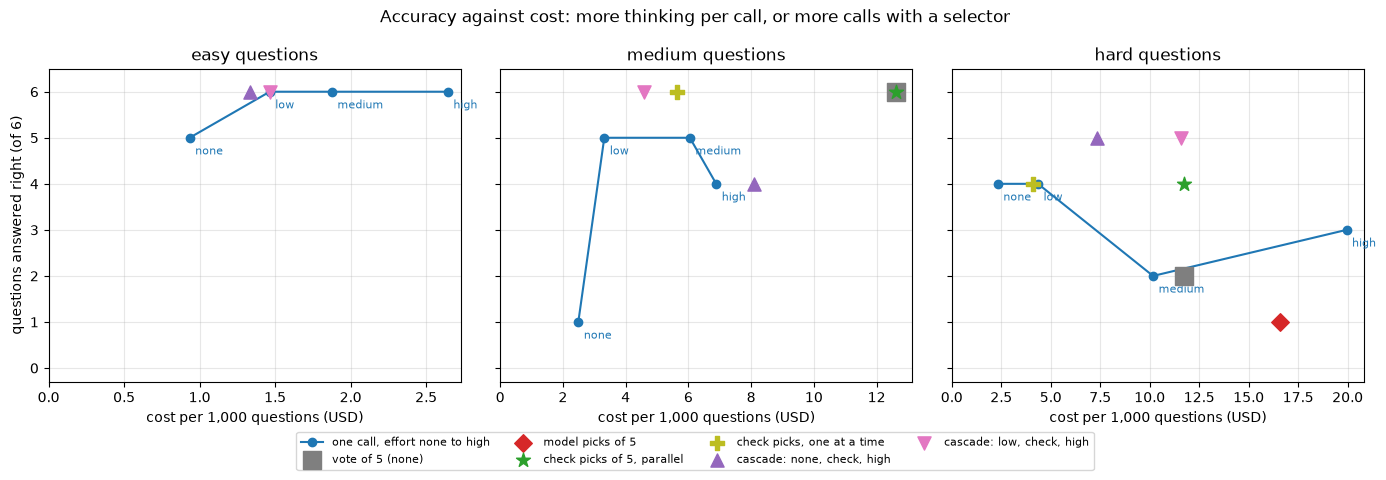

In [10]:
def outcome(answer, used, parallel=True):
    secs = max(u["seconds"] for u in used) if parallel else sum(u["seconds"] for u in used)
    return {"right": bool(answer and answer["right"]), "wrong": bool(answer and not answer["right"]), "none": answer is None,
            "usd": sum(u["usd"] for u in used), "seconds": secs, "output": sum(u["output"] for u in used)}

def strategies(it):
    s, cs = {}, CANDS.get(it["id"])
    for e in EFFORTS:
        a = SWEEP[(it["id"], e)]
        s[f"one call, {e}"] = outcome(a, [a])
    a = SWEEP[(it["id"], "high")]
    s["one call, high + check"] = outcome(a if a["passes"] else None, [a])
    for first in ("none", "low"):
        ans, used = cascade(it, first)
        s[f"cascade: {first}, check, high"] = outcome(ans, used, parallel=False)
    if cs:
        s[f"vote of {N} (none)"] = outcome(by_vote(cs)[0], cs)
        if it["id"] in PICKS:
            pick, p = PICKS[it["id"]]
            o = outcome(pick, cs + [p]); o["seconds"] = max(c["seconds"] for c in cs) + p["seconds"]; s[f"model picks of {N}"] = o
        s[f"check picks of {N}, parallel"] = outcome(by_check(cs)[0], cs)
        c, k = by_check(cs)
        s[f"check picks, one at a time"] = outcome(c, cs[:k], parallel=False)
    return s

TABLE = {}
for tier in TIERS:
    per_item = [strategies(it) for it in tier_items(tier)]
    for name in max(per_item, key=len):
        rows = [p[name] for p in per_item]
        TABLE[(tier, name)] = {k: sum(r[k] for r in rows) / (1 if k in ("right", "wrong", "none") else len(rows)) for k in rows[0]}

for tier in ("medium", "hard"):
    n = len(tier_items(tier))
    print(f"{tier.upper():34}{'right':>6}{'wrong':>7}{'no answer':>11}{'$ / question':>14}{'seconds':>9}{'output tok':>12}")
    for (t, name), r in TABLE.items():
        if t == tier:
            print(f"  {name:32}{r['right']:>4.0f}/{n}{r['wrong']:>7.0f}{r['none']:>11.0f}{r['usd']:>14.4f}{r['seconds']:>9.1f}{r['output']:>12,.0f}")
    print()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
styles = {f"vote of {N} (none)": ("s", "tab:gray", 150), f"model picks of {N}": ("D", "tab:red", 80),
          f"check picks of {N}, parallel": ("*", "tab:green", 110), "check picks, one at a time": ("P", "tab:olive", 90),
          "cascade: none, check, high": ("^", "tab:purple", 90), "cascade: low, check, high": ("v", "tab:pink", 90)}
for ax, tier in zip(axes, TIERS):
    xs = [TABLE[(tier, f"one call, {e}")]["usd"] * 1000 for e in EFFORTS]
    ys = [TABLE[(tier, f"one call, {e}")]["right"] for e in EFFORTS]
    ax.plot(xs, ys, "o-", color="tab:blue", label="one call, effort none to high")
    for e, x, y in zip(EFFORTS, xs, ys):
        ax.annotate(e, (x, y), textcoords="offset points", xytext=(4, -12), fontsize=8, color="tab:blue")
    for name, (m, col, size) in styles.items():
        if (tier, name) in TABLE:
            r = TABLE[(tier, name)]
            ax.scatter(r["usd"] * 1000, r["right"], marker=m, s=size, color=col, label=name, zorder=3)
    ax.set_title(f"{tier} questions"); ax.set_xlabel("cost per 1,000 questions (USD)"); ax.grid(alpha=0.3)
    ax.set_xlim(left=0); ax.set_ylim(-0.3, len(tier_items(tier)) + 0.5)
axes[0].set_ylabel(f"questions answered right (of {len(tier_items('easy'))})")
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Accuracy against cost: more thinking per call, or more calls with a selector")
plt.tight_layout(); plt.show()

### What the numbers say, and what they don't

- **Effort is a per-tier dial, and each tier wanted a different setting.** On easy questions, nothing past `low` bought anything, and `none` missed only one of six. On medium questions, `low` was the level to keep: it matched `high` within noise (5 against 4 of 6 in this run, 15 against 16 of 18 pooled over three runs) at under half the cost. On hard questions, no single level was good enough on its own.
- **On hard questions, one `high` call cost the most and bought little.** It got 3 of 6 right and shipped 3 wrong answers, at $0.0199 and 26 seconds per question. The cascade got 5 of 6 with no wrong answer, at $0.0116 starting from `low` or $0.0073 starting from `none`. Checking attempts one at a time got 4 of 6 for $0.0041, about a fifth of one `high` call.
- **The selector decided whether search paid.** From the same five attempts per question, the check kept 4 of 6 hard answers right, the vote 2, and the model picker 1. Taking the first attempt and stopping also scored 4 (that is `one call, none`), but this run's first attempts were lucky: only 8 of all 30 `none` attempts at hard questions were right, so one attempt can be expected to get about 1.6 of the 6. The check got 4, while the vote and the picker did no better than one attempt can be expected to.
- **A check also turns wrong answers into refusals.** `one call, high + check` shipped no wrong answers on either tier, at the price of refusing 2 medium and 3 hard questions. The strategies that used the check shipped at most 2 wrong answers out of 6, and every one of those was the misread section 7 shows the check cannot see.
- **Thinking costs seconds, parallel attempts mostly don't.** `high` took 26 seconds per hard question against 3.3 for `none`. Five `none` attempts in parallel took 3.7 seconds. Reasoning was 55,213 of the run's 101,713 output tokens.
- **Noise is the biggest caveat.** Six questions per tier, one attempt per level, and the model is not deterministic. Across three runs, the hard tier at `high` scored 2, 5 and 3 of 6, and at `none` 1, 0 and 4, so a single run's ranking of effort levels on hard questions is mostly noise. The pooled numbers (5, 5, 7 and 10 of 18 from `none` to `high`) say `high` about doubled the hit rate of `none` there, at about 8.7 times the price in this run. **This notebook does not show that `high` is worse than `none` on hard questions**, even though this run's table says so. To choose a level for your own agent, use more questions or more repeats than this.

## 7. What went wrong, and what the check cannot see

The answer key can be recomputed with one rule misread on purpose. When a wrong answer matches such a key to the cent, we know which rule its query got wrong. Three misreads per tier are tested, alone and in pairs:

- **medium:** dropping USD rows (an inner join to `fx_rates`), subtracting only the credit notes on this quarter's invoices, and converting a credit note at its invoice's rate instead of its own
- **hard:** dropping USD rows, computing a cancelled subscription's daily rate over the days it served instead of its full term, and crediting the customer's current region instead of the region on the start date

In [11]:
MISREADS = {"medium": ["USD dropped", "credits on this quarter's invoices only", "credit at the invoice's rate"],
            "hard": ["USD dropped", "rate over days served", "current region"]}
METRIC = {tier: metric for tier, (metric, _) in TIERS.items()}

def diagnose(a, tier):                 # which misread rules reproduce this wrong answer exactly?
    q, seg = a["id"].split("-")[1:]
    rules = MISREADS[tier]
    for combo in [(r,) for r in rules] + [(r1, r2) for i, r1 in enumerate(rules) for r2 in rules[i + 1:]]:
        if matches_key(a["result"], VARIANTS[combo][(METRIC[tier], q, seg)]):
            return " + ".join(combo)
    return "query failed to run" if a["result"] is None else "none of these misreads"

VARIANTS = {combo: answer_key(TABLES, combo) for tier in MISREADS for combo in
            [(r,) for r in MISREADS[tier]] + [(r1, r2) for i, r1 in enumerate(MISREADS[tier]) for r2 in MISREADS[tier][i + 1:]]}
attempts = list(SWEEP.values()) + [c for cs in CANDS.values() for c in cs[1:]]
for tier in ("medium", "hard"):
    for effort in EFFORTS:
        wrong = [a for a in attempts if a["id"].startswith(tier) and a["effort"] == effort and not a["right"]]
        if wrong:
            print(f"{tier:7}{effort:7}{len(wrong):>3} wrong: " + ", ".join(f"{n} {d}" for d, n in Counter(diagnose(a, tier) for a in wrong).most_common()))
    print()

passed = [a for a in attempts if a["passes"]]
fooled = [a for a in passed if not a["right"]]
print(f"{len(attempts)} queries written, {len(passed)} passed the check, {len(fooled)} of those were wrong: "
      + ", ".join(f"{a['id']} ({diagnose(a, a['id'].split('-')[0])})" for a in fooled))
print("\nThe 'current region' misread on every hard question:")
for it in tier_items("hard"):
    q, seg = it["id"].split("-")[1:]
    r = VARIANTS[("current region",)][("recognized", q, seg)]
    print(f"  {it['id']:22} passes the check: {reconciles(r, CLOSE_REPORT[it['id']])!s:5}  right: {matches_key(r, it['truth'])}")

medium none    17 wrong: 10 query failed to run, 7 none of these misreads
medium low      1 wrong: 1 query failed to run
medium medium   1 wrong: 1 query failed to run
medium high     2 wrong: 2 query failed to run

hard   none    22 wrong: 5 none of these misreads, 5 query failed to run, 4 USD dropped, 3 rate over days served, 3 current region, 1 rate over days served + current region, 1 USD dropped + current region
hard   low      2 wrong: 1 USD dropped, 1 none of these misreads
hard   medium   4 wrong: 4 rate over days served
hard   high     3 wrong: 2 rate over days served, 1 none of these misreads

120 queries written, 70 passed the check, 3 of those were wrong: hard-Q2-Enterprise (current region), hard-Q2-Enterprise (current region), hard-Q3-SMB (current region)

The 'current region' misread on every hard question:
  hard-Q1-Enterprise     passes the check: True   right: False
  hard-Q1-SMB            passes the check: True   right: False
  hard-Q2-Enterprise     passes the check

Three findings:

- **More thinking fixed the slips, not the misreading.** At `none`, the wrong hard answers were a mix of every kind: dropped USD rows, the daily-rate misread, the current region, queries that failed, and answers that matched none of the misreads. At `medium` and `high`, 6 of the 7 wrong hard answers were one misread: the daily rate of a cancelled subscription computed over the days it served, although the glossary says the rate does not change. In the run before this one, all 4 wrong `medium` and `high` hard answers were the same misread. That is doubt about what a definition means, and more effort did not settle it. The next thing to test is a worked example in the glossary, not a higher level.
- **On medium questions, the wrong answers above `none` were queries that did not run.** All 4 wrong answers at `low`, `medium` and `high` failed to run: a SQL error, a result in the wrong shape, or the five-second limit (the notebook does not record which). None was a wrong number. At `none`, 10 of the 17 wrong medium answers failed to run, and the other 7 matched none of the misreads tested.
- **The check has a blind spot, and search found it.** 70 of the 120 queries passed the check, and 3 of those were wrong. All 3 credited revenue to the customer's current region. That misread moves money between regions without changing the total, so it passes the check on every hard question, as the last printout shows. The more attempts you make, the more chances one of them has to pass for the wrong reason. A second check that this misread cannot pass, such as per-region bookings from the sales system, would close it.

The bill for this run, from the API's `usage` fields:

In [12]:
print(f"{len(CALLS)} API calls, {sum(c['input'] for c in CALLS):,} input tokens ({sum(c['cached'] for c in CALLS):,} cached), "
      f"{sum(c['output'] for c in CALLS):,} output tokens of which {sum(c['reasoning'] for c in CALLS):,} reasoning")
print(f"total cost ${sum(c['usd'] for c in CALLS):.3f}, {(time.time() - T_START) / 60:.1f} minutes since the first cell")

128 API calls, 87,408 input tokens (0 cached), 101,713 output tokens of which 55,213 reasoning
total cost $0.523, 1.2 minutes since the first cell


## The fact to walk away with

Extra thinking paid on some questions and not on others, so set it per kind of step, on questions with known answers. Here the first step, from `none` to `low`, lifted the medium tier from 1 to 5 of 6 and fixed the one easy miss. Every step past `low` bought nothing on the easy and medium tiers, and no level fixed the definition the hard tier misread. Extra attempts were only as good as the selector. A check in code paid on both tiers. A vote worked on medium questions, where wrong answers scattered, and failed on hard ones, where attempts shared mistakes. The model picker did worst of all. The best setup in this run was one `low` attempt, the check, and `high` only when the check failed. It got 17 of 18 right and shipped no wrong answer, against 13 right and 5 wrong for `high` on every question, at about 60% of the cost. Six questions per tier is a small sample and three runs disagreed on the hard tier, so measure on your own questions before you set a level.

What to try next:

- **Fix the misread, then turn the dial again.** Add a worked example of a cancelled subscription to the glossary and rerun section 3. If the hard tier jumps at `low`, the problem was context, not thinking.
- **Close the blind spot.** Add a second check that the current-region misread cannot pass, and watch the `wrong` column of the check strategies.
- **Try `xhigh`** on the hard tier only, and see whether it buys anything over `high` for its price.
- **Let the agent look before it answers.** Give it a tool to run a few exploratory queries (the [while-loop notebook](agent_while_loop_from_scratch.ipynb) builds that loop). Doubt about what the data looks like is settled by one query, not by thinking longer ([The Danger of Overthinking, 2025](https://arxiv.org/abs/2502.08235)).
- **Grow the sample.** Add quarters, segments or repeats per question until the ranking of effort levels stops flipping between runs.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--thinking-budgets-from-scratch&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-thinking-budgets&retarget=0&text=book-nb-agents) by the author of this repository has a full chapter on search and thinking budgets: best-of-n, voting, the selector that decides what you get, the thinking budget, and when more effort makes answers worse. Available on Amazon.

![](https://europe-west1-genai-agents-views-tracker.cloudfunctions.net/genai-agents-tracker?notebook=all-agents-tutorials--thinking-budgets-from-scratch)